In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [41]:
df = pd.read_csv("E-commerce_Customer_Segmentation_2026.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (50000, 53)


In [42]:
df.head()

,customer_id,customer_segment,segment_category,age,age_group,gender,country,city,income_bracket,education_level,...,customer_value_category,activity_status,health_status,churn_risk_category,rfm_category,profitability_category,engagement_level,behavior_segment,device_preference,clv_category
0,CUST-000001,Consumer,High Value Inactive,70,65+,Male,Canada,Winnipeg,150K+,Professional,...,High,Dormant,Excellent,Low,Potential Loyalists,High Profit,Low,Regular Buyer,Multi-Device,High CLV
1,CUST-000002,Premium,High Value Inactive,53,45-54,Female,Germany,Essen,25K-50K,High School,...,Medium,Inactive,Excellent,Medium,At Risk,High Profit,Low,Occasional Buyer,Desktop-First,High CLV
2,CUST-000003,Consumer,High Value Inactive,82,65+,Male,Mexico,Puebla,75K-100K,Bachelors,...,Very High,Dormant,Excellent,Very Low,Champions,High Profit,Low,Regular Buyer,Multi-Device,High CLV
3,CUST-000004,Enterprise,High Value Active,18,18-24,Male,Singapore,Singapore,150K+,Masters,...,Very High,Active,Excellent,Very Low,Champions,High Profit,High,Frequent Buyer,Mobile-First,High CLV
4,CUST-000005,Premium,High Value Active,64,55-64,Male,United Arab Emirates,Fujairah,150K+,PhD,...,Medium,Active,Fair,Medium,Loyal,High Profit,Medium,Occasional Buyer,Desktop-First,High CLV


In [43]:
df.columns

Index(['customer_id', 'customer_segment', 'segment_category', 'age',
       'age_group', 'gender', 'country', 'city', 'income_bracket',
       'education_level', 'employment_type', 'marital_status', 'tenure_months',
       'total_purchases', 'avg_order_value_usd', 'total_spent_usd',
       'purchase_frequency', 'days_since_last_purchase',
       'preferred_category_1', 'preferred_category_2', 'preferred_category_3',
       'shopping_channel', 'device_used', 'payment_method', 'return_count',
       'complaint_count', 'satisfaction_score', 'satisfaction_level',
       'loyalty_tier', 'email_open_rate', 'click_through_rate',
       'conversion_rate', 'social_media_presence',
       'customer_lifetime_value_usd', 'customer_acquisition_cost_usd',
       'customer_profitability_usd', 'recency_score', 'frequency_score',
       'monetary_score', 'rfm_score', 'churn_risk_score',
       'customer_health_score', 'dataset_year', 'customer_value_category',
       'activity_status', 'health_status',

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 53 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    50000 non-null  str    
 1   customer_segment               50000 non-null  str    
 2   segment_category               50000 non-null  str    
 3   age                            50000 non-null  int64  
 4   age_group                      50000 non-null  str    
 5   gender                         50000 non-null  str    
 6   country                        50000 non-null  str    
 7   city                           50000 non-null  str    
 8   income_bracket                 50000 non-null  str    
 9   education_level                50000 non-null  str    
 10  employment_type                50000 non-null  str    
 11  marital_status                 50000 non-null  str    
 12  tenure_months                  50000 non-null  int64  
 1

In [45]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

missing_values

preferred_category_3     33257
preferred_category_2     16743
social_media_presence    12420
loyalty_tier              1272
dtype: int64

In [46]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_percentage = missing_percentage[
    missing_percentage > 0
].sort_values(ascending=False)

missing_percentage

preferred_category_3     66.514
preferred_category_2     33.486
social_media_presence    24.840
loyalty_tier              2.544
dtype: float64

In [47]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [48]:
print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

Duplicate customer IDs: 0


In [49]:
df["churn_risk_category"].value_counts()

churn_risk_category
Very Low     20604
Low          17203
Medium        9491
High          2395
Very High      307
Name: count, dtype: int64

In [50]:
df["churn_risk_category"].value_counts(normalize=True) * 100

churn_risk_category
Very Low     41.208
Low          34.406
Medium       18.982
High          4.790
Very High     0.614
Name: proportion, dtype: float64

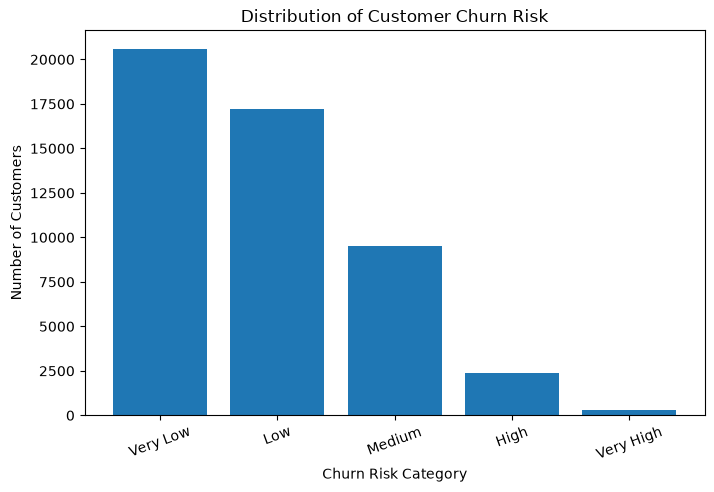

In [51]:
risk_order = [
    "Very Low",
    "Low",
    "Medium",
    "High",
    "Very High"
]

risk_counts = df["churn_risk_category"].value_counts().reindex(risk_order)

plt.figure(figsize=(8,5))

plt.bar(risk_counts.index, risk_counts.values)

plt.title("Distribution of Customer Churn Risk")
plt.xlabel("Churn Risk Category")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

In [52]:
df["high_risk_flag"] = df["churn_risk_category"].isin(
    ["High", "Very High"]
).astype(int)

In [53]:
df["high_risk_flag"].value_counts()

high_risk_flag
0    47298
1     2702
Name: count, dtype: int64

In [54]:
df["high_risk_flag"].value_counts(normalize=True) * 100

high_risk_flag
0    94.596
1     5.404
Name: proportion, dtype: float64

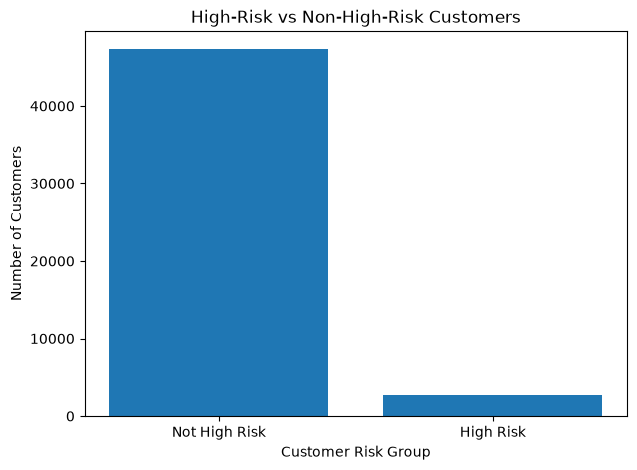

In [55]:
risk_flag_counts = df["high_risk_flag"].value_counts().sort_index()

plt.figure(figsize=(7,5))

plt.bar(
    ["Not High Risk", "High Risk"],
    risk_flag_counts.values
)

plt.title("High-Risk vs Non-High-Risk Customers")
plt.xlabel("Customer Risk Group")
plt.ylabel("Number of Customers")

plt.show()

In [56]:
numeric_features = [
    "age",
    "tenure_months",
    "total_purchases",
    "avg_order_value_usd",
    "total_spent_usd",
    "days_since_last_purchase",
    "return_count",
    "complaint_count",
    "satisfaction_score",
    "email_open_rate",
    "click_through_rate",
    "conversion_rate"
]

risk_comparison = df.groupby("high_risk_flag")[numeric_features].mean().T

risk_comparison.columns = ["Not High Risk", "High Risk"]

risk_comparison

,Not High Risk,High Risk
age,45.626665,46.021836
tenure_months,59.766015,59.437084
total_purchases,99.906254,90.879719
avg_order_value_usd,505.967747,494.849378
total_spent_usd,50556.193470,45196.324597
days_since_last_purchase,56.121464,182.875278
return_count,9.291365,13.369356
complaint_count,6.848387,9.539230
satisfaction_score,3.081906,1.713546
email_open_rate,0.501146,0.485843


In [57]:
df.groupby("churn_risk_category")["churn_risk_score"].agg(
    ["min", "max", "mean", "median"]
)

,min,max,mean,median
churn_risk_category,,,,
High,61,80,67.513152,66.0
Low,21,40,29.950183,30.0
Medium,41,60,48.615109,48.0
Very High,81,100,85.869707,85.0
Very Low,0,20,8.608328,8.0


In [58]:
df.groupby("churn_risk_category")[
    ["recency_score", "frequency_score", "monetary_score", "rfm_score"]
].mean()

,recency_score,frequency_score,monetary_score,rfm_score
churn_risk_category,,,,
High,2.122756,3.932777,3.514405,9.569937
Low,3.994652,4.119340,3.716968,11.830960
Medium,3.220209,4.050153,3.653777,10.924139
Very High,1.508143,3.368078,3.013029,7.889251
Very Low,4.507474,4.192293,3.781887,12.481654


In [59]:
df.groupby("churn_risk_category")["churn_risk_score"].agg(
    ["min", "max", "mean", "median"]
)

,min,max,mean,median
churn_risk_category,,,,
High,61,80,67.513152,66.0
Low,21,40,29.950183,30.0
Medium,41,60,48.615109,48.0
Very High,81,100,85.869707,85.0
Very Low,0,20,8.608328,8.0


In [60]:
df.groupby("churn_risk_category")[
    ["recency_score", "frequency_score", "monetary_score", "rfm_score"]
].mean()

,recency_score,frequency_score,monetary_score,rfm_score
churn_risk_category,,,,
High,2.122756,3.932777,3.514405,9.569937
Low,3.994652,4.119340,3.716968,11.830960
Medium,3.220209,4.050153,3.653777,10.924139
Very High,1.508143,3.368078,3.013029,7.889251
Very Low,4.507474,4.192293,3.781887,12.481654


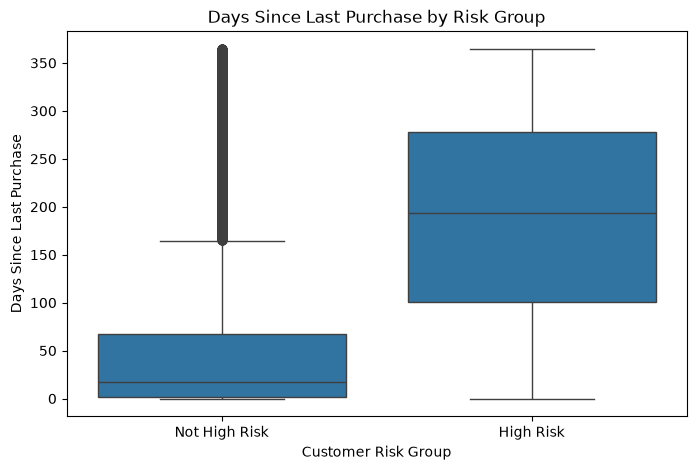

In [61]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="high_risk_flag",
    y="days_since_last_purchase"
)

plt.xticks(
    [0, 1],
    ["Not High Risk", "High Risk"]
)

plt.title("Days Since Last Purchase by Risk Group")
plt.xlabel("Customer Risk Group")
plt.ylabel("Days Since Last Purchase")

plt.show()

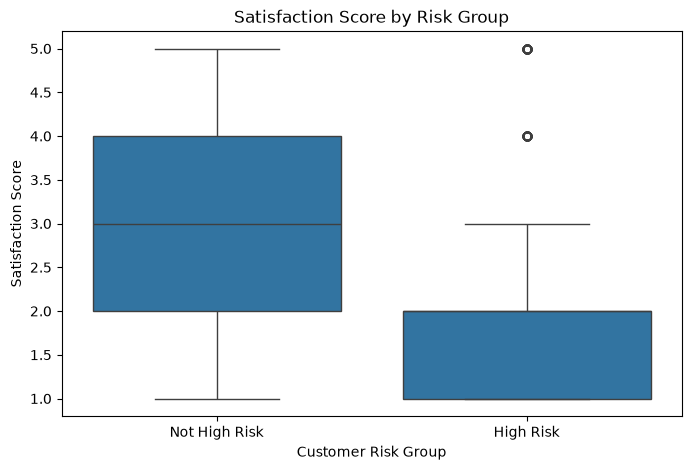

In [62]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="high_risk_flag",
    y="satisfaction_score"
)

plt.xticks(
    [0, 1],
    ["Not High Risk", "High Risk"]
)

plt.title("Satisfaction Score by Risk Group")
plt.xlabel("Customer Risk Group")
plt.ylabel("Satisfaction Score")

plt.show()

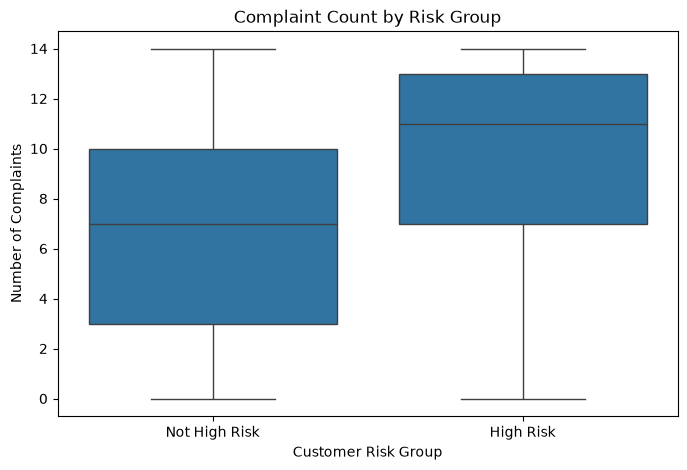

In [63]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="high_risk_flag",
    y="complaint_count"
)

plt.xticks(
    [0, 1],
    ["Not High Risk", "High Risk"]
)

plt.title("Complaint Count by Risk Group")
plt.xlabel("Customer Risk Group")
plt.ylabel("Number of Complaints")

plt.show()

In [64]:
# Features to exclude because they directly encode or define churn risk

exclude_columns = [
    "customer_id",
    "customer_segment",
    "segment_category",
    "churn_risk_category",
    "churn_risk_score",
    "recency_score",
    "frequency_score",
    "monetary_score",
    "rfm_score",
    "high_risk_flag"
]

# Create feature dataset
X = df.drop(columns=exclude_columns)

# Target variable
y = df["high_risk_flag"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (50000, 44)
Target shape: (50000,)

Target distribution:
high_risk_flag
0    47298
1     2702
Name: count, dtype: int64


In [65]:
# Outlier analysis using the IQR method

numeric_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

outlier_summary = []

for col in numeric_columns:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (X[col] < lower_bound) |
        (X[col] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Outlier_Count": outliers,
        "Outlier_Percentage": round(
            outliers / len(X) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary = outlier_summary.sort_values(
    by="Outlier_Count",
    ascending=False
)

outlier_summary

,Feature,Outlier_Count,Outlier_Percentage
5,days_since_last_purchase,6460,12.92
14,customer_profitability_usd,1080,2.16
12,customer_lifetime_value_usd,1078,2.16
4,total_spent_usd,582,1.16
15,customer_health_score,263,0.53
0,age,0,0.00
3,avg_order_value_usd,0,0.00
2,total_purchases,0,0.00
1,tenure_months,0,0.00
8,satisfaction_score,0,0.00


In [66]:
# Correlation analysis

correlation = X.select_dtypes(
    include=["int64", "float64"]
).corr()

# Correlation with the target variable
target_correlation = pd.concat(
    [X.select_dtypes(include=["int64", "float64"]), y],
    axis=1
).corr()["high_risk_flag"].sort_values(
    ascending=False
)

target_correlation

high_risk_flag                   1.000000
days_since_last_purchase         0.307231
return_count                     0.159449
complaint_count                  0.140694
age                              0.004864
conversion_rate                  0.001636
tenure_months                   -0.002168
click_through_rate              -0.003758
customer_acquisition_cost_usd   -0.004270
avg_order_value_usd             -0.008802
email_open_rate                 -0.011952
customer_profitability_usd      -0.026400
customer_lifetime_value_usd     -0.026404
total_spent_usd                 -0.027498
total_purchases                 -0.035322
satisfaction_score              -0.218188
customer_health_score           -0.338649
dataset_year                          NaN
Name: high_risk_flag, dtype: float64

In [67]:
# Check missing values
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

missing_values

preferred_category_3     33257
preferred_category_2     16743
social_media_presence    12420
loyalty_tier              1272
dtype: int64

In [68]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (40000, 44)
Testing feature shape: (10000, 44)
Training target shape: (40000,)
Testing target shape: (10000,)


In [69]:
from sklearn.model_selection import train_test_split

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training dataset shape: (40000, 44)
Testing dataset shape: (10000, 44)

Training target distribution:
high_risk_flag
0    37838
1     2162
Name: count, dtype: int64

Testing target distribution:
high_risk_flag
0    9460
1     540
Name: count, dtype: int64


In [70]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


C:\Users\jayee\AppData\Local\Temp\ipykernel_23516\4069671032.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [71]:
from sklearn.linear_model import LogisticRegression

# Logistic Regression model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [72]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest model
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [73]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Models
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = []

for name, model in models.items():

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Probability predictions for ROC-AUC
    y_train_prob = model.predict_proba(X_train)[:, 1]
    y_test_prob = model.predict_proba(X_test)[:, 1]

    # Training metrics
    train_accuracy = accuracy_score(y_train, y_train_pred)
    
    # Testing metrics
    test_accuracy = accuracy_score(y_test, y_test_pred)
    test_precision = precision_score(y_test, y_test_pred, zero_division=0)
    test_recall = recall_score(y_test, y_test_pred, zero_division=0)
    test_f1 = f1_score(y_test, y_test_pred, zero_division=0)
    test_roc_auc = roc_auc_score(y_test, y_test_prob)

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Test Precision": test_precision,
        "Test Recall": test_recall,
        "Test F1": test_f1,
        "Test ROC-AUC": test_roc_auc
    })

results_df = pd.DataFrame(results)

results_df

,Model,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Logistic Regression,0.925150,0.9227,0.404430,0.912963,0.560546,0.97526
1,Random Forest,0.997875,0.9725,0.751423,0.733333,0.742268,0.98230


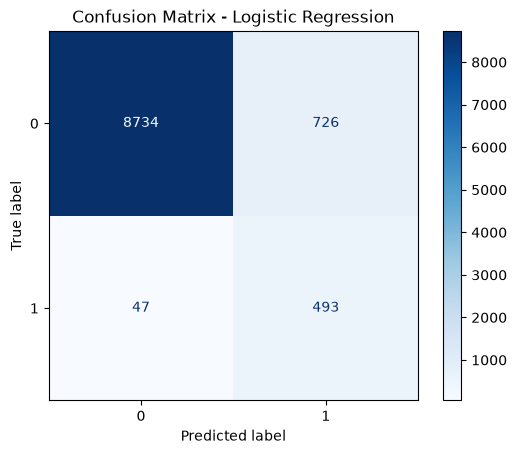

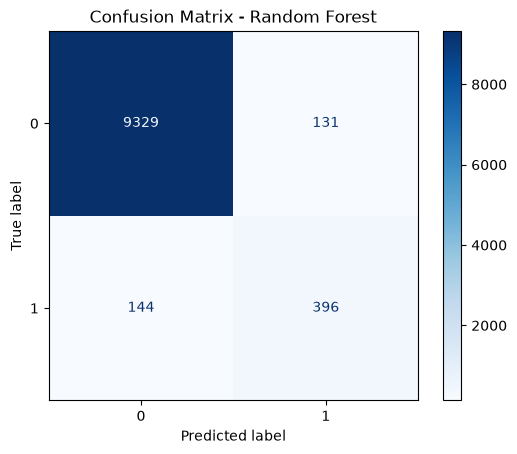

In [74]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():

    y_test_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_test_pred,
        cmap="Blues"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.show()

In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

comparison = []

for name, model in models.items():

    # Training predictions
    y_train_pred = model.predict(X_train)
    y_train_prob = model.predict_proba(X_train)[:, 1]

    # Testing predictions
    y_test_pred = model.predict(X_test)
    y_test_prob = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,

        "Train Accuracy": accuracy_score(y_train, y_train_pred),
        "Test Accuracy": accuracy_score(y_test, y_test_pred),

        "Train Precision": precision_score(
            y_train, y_train_pred, zero_division=0
        ),
        "Test Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Train Recall": recall_score(
            y_train, y_train_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Train F1": f1_score(
            y_train, y_train_pred, zero_division=0
        ),
        "Test F1": f1_score(
            y_test, y_test_pred, zero_division=0
        ),

        "Train ROC-AUC": roc_auc_score(
            y_train, y_train_prob
        ),
        "Test ROC-AUC": roc_auc_score(
            y_test, y_test_prob
        )
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,Model,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1,Test F1,Train ROC-AUC,Test ROC-AUC
0,Logistic Regression,0.925150,0.9227,0.417395,0.404430,0.972248,0.912963,0.584051,0.560546,0.982018,0.97526
1,Random Forest,0.997875,0.9725,0.962172,0.751423,1.000000,0.733333,0.980721,0.742268,1.000000,0.98230


In [76]:
# Train-Test Performance Gap

comparison_df["Accuracy Gap"] = (
    comparison_df["Train Accuracy"] -
    comparison_df["Test Accuracy"]
)

comparison_df["F1 Gap"] = (
    comparison_df["Train F1"] -
    comparison_df["Test F1"]
)

comparison_df["ROC-AUC Gap"] = (
    comparison_df["Train ROC-AUC"] -
    comparison_df["Test ROC-AUC"]
)

comparison_df[
    [
        "Model",
        "Accuracy Gap",
        "F1 Gap",
        "ROC-AUC Gap"
    ]
]

,Model,Accuracy Gap,F1 Gap,ROC-AUC Gap
0,Logistic Regression,0.002450,0.023505,0.006758
1,Random Forest,0.025375,0.238453,0.017700


In [77]:
# Train-Test Performance Gap

comparison_df["Accuracy Gap"] = (
    comparison_df["Train Accuracy"] -
    comparison_df["Test Accuracy"]
)

comparison_df["F1 Gap"] = (
    comparison_df["Train F1"] -
    comparison_df["Test F1"]
)

comparison_df["ROC-AUC Gap"] = (
    comparison_df["Train ROC-AUC"] -
    comparison_df["Test ROC-AUC"]
)

comparison_df[
    [
        "Model",
        "Accuracy Gap",
        "F1 Gap",
        "ROC-AUC Gap"
    ]
]

,Model,Accuracy Gap,F1 Gap,ROC-AUC Gap
0,Logistic Regression,0.002450,0.023505,0.006758
1,Random Forest,0.025375,0.238453,0.017700


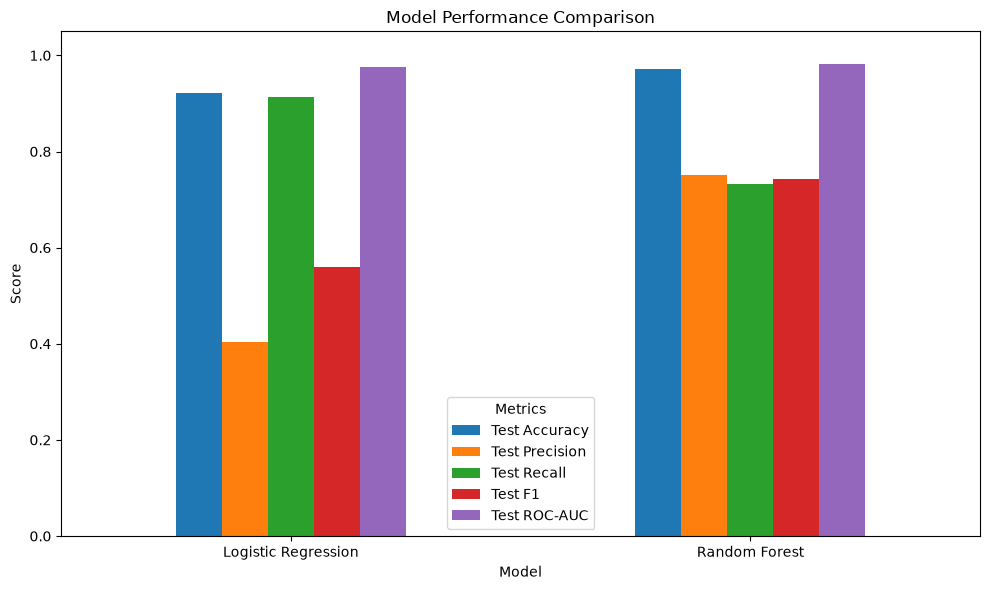

In [78]:
import matplotlib.pyplot as plt

# Model performance comparison
metrics = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1",
    "Test ROC-AUC"
]

comparison_plot = comparison_df.set_index("Model")[metrics]

comparison_plot.plot(kind="bar", figsize=(10, 6))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

## Final Model Comparison and Conclusion

Two classification models, Logistic Regression and Random Forest, were trained and evaluated for predicting customer high-risk status.

### Model Comparison

Random Forest achieved better overall test performance than Logistic Regression. Its test accuracy was 97.25%, compared with 92.27% for Logistic Regression. Random Forest also achieved higher test precision (75.14%), F1-score (74.23%), and ROC-AUC (98.23%).

Logistic Regression achieved a higher test recall of 91.30%, compared with 73.33% for Random Forest. This indicates that Logistic Regression was better at identifying customers who actually belonged to the high-risk class.

### Train vs Test Analysis

Logistic Regression showed a very small accuracy gap of 0.00245, F1 gap of 0.02351, and ROC-AUC gap of 0.00676. This indicates stable performance between training and unseen testing data and suggests good generalization with little evidence of overfitting.

Random Forest showed an accuracy gap of 0.02538 and a larger F1 gap of 0.23845. This indicates some degree of overfitting. However, its test performance remained strong, with 97.25% accuracy and 98.23% ROC-AUC.

### Final Conclusion

Based on the evaluation results, Random Forest is selected as the better overall model because it provides higher test accuracy, precision, F1-score, and ROC-AUC. However, Logistic Regression has substantially higher recall and a smaller train-test performance gap.

Therefore, Random Forest provides the strongest overall predictive performance, while Logistic Regression provides more consistent generalization and is more effective when identifying as many high-risk customers as possible is the primary objective.

The analysis demonstrates the complete machine learning workflow from dataset understanding and EDA through train-test splitting, model training, testing, confusion matrix analysis, performance comparison, train-test analysis, and final model selection.